In [1]:
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print("Python executable:", sys.executable)
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Scikit-learn version:", sklearn.__version__)
print("\nNotebook environment is ready!")

Python executable: c:\Users\ADMIN\Desktop\food-surplus-spoilage-predictor\.venv\Scripts\python.exe
Pandas version: 3.1.1
NumPy version: 2.5.4
Scikit-learn version: 1.9.1

Notebook environment is ready!


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)

train_df = pd.read_excel("../data/train.csv.xlsx")

print("Dataset loaded successfully!")
print("Shape:", train_df.shape)

display(train_df.head())

Dataset loaded successfully!
Shape: (911, 12)


,ID,date,meals_served,kitchen_staff,temperature_C,humidity_percent,day_of_week,special_event,past_waste_kg,staff_experience,waste_category,food_waste_kg
0,0,2022-12-19,196,13,27.887273,45.362854,0,0,7.740587,intermediate,dairy,28.946465
1,1,2023-11-21,244,15,10.317872,64.430475,1,0,42.311779,NaN,MeAt,51.549053
2,4,2022-02-01,148,16,27.714300,69.046113,1,0,41.184305,Beginner,MeAt,53.008323
3,5,2023-03-19,157,19,19.173902,46.292823,6,0,41.543492,Beginner,MeAt,48.621527
4,6,2022-07-18,297,10,26.375233,79.741064,0,0,26.525097,Intermediate,MEAT,44.156984


In [7]:
print("Column Names:")
print(train_df.columns.tolist())

print("\nDataset Information:")
train_df.info()

Column Names:
['ID', 'date', 'meals_served', 'kitchen_staff', 'temperature_C', 'humidity_percent', 'day_of_week', 'special_event', 'past_waste_kg', 'staff_experience', 'waste_category', 'food_waste_kg']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 911 entries, 0 to 910
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   ID                911 non-null    int64         
 1   date              911 non-null    datetime64[us]
 2   meals_served      911 non-null    int64         
 3   kitchen_staff     911 non-null    int64         
 4   temperature_C     911 non-null    float64       
 5   humidity_percent  911 non-null    float64       
 6   day_of_week       911 non-null    int64         
 7   special_event     911 non-null    int64         
 8   past_waste_kg     911 non-null    float64       
 9   staff_experience  747 non-null    str           
 10  waste_category    911 non-nu

In [8]:
missing_values = train_df.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": (missing_values / len(train_df)) * 100
})

display(missing_summary)

,Missing Values,Missing Percentage
ID,0,0.000000
date,0,0.000000
meals_served,0,0.000000
kitchen_staff,0,0.000000
temperature_C,0,0.000000
humidity_percent,0,0.000000
day_of_week,0,0.000000
special_event,0,0.000000
past_waste_kg,0,0.000000
staff_experience,164,18.002195


In [9]:
print("Number of duplicate rows:", train_df.duplicated().sum())

Number of duplicate rows: 0


In [10]:

# Statistical summary of numerical columns

display(train_df.describe().T)


,count,mean,min,25%,50%,75%,max,std
ID,911.0,528.327113,0.0,266.0,531.0,795.5,1049.0,305.072794
date,911,2023-04-22 09:30:37.541163,2022-01-01 00:00:00,2022-07-25 12:00:00,2023-04-23 00:00:00,2024-01-07 12:00:00,2024-09-26 00:00:00,NaN
meals_served,911.0,375.405049,100.0,211.0,306.0,407.0,4730.0,502.812717
kitchen_staff,911.0,11.90011,5.0,8.0,12.0,15.0,19.0,4.285153
temperature_C,911.0,22.18928,-10.372207,15.684585,22.11504,28.804294,60.0,8.922389
humidity_percent,911.0,60.761313,30.121111,46.017835,61.63396,75.78791,89.982828,17.330821
day_of_week,911.0,3.01427,0.0,1.0,3.0,5.0,6.0,2.009542
special_event,911.0,0.08562,0.0,0.0,0.0,0.0,1.0,0.279956
past_waste_kg,911.0,27.015691,5.008394,16.091383,26.854109,38.149878,49.803703,12.774223
food_waste_kg,911.0,44.842691,10.819048,32.887912,41.14693,50.046681,274.328783,27.934366


In [11]:

# Identify categorical columns

categorical_cols = train_df.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Categorical columns:", categorical_cols)

for col in categorical_cols:
    print(f"\nUnique values in {col}:")
    print(train_df[col].value_counts(dropna=False))


Categorical columns: ['staff_experience', 'waste_category']

Unique values in staff_experience:
staff_experience
Beginner        191
Intermediate    186
EXPERT          186
intermediate    184
NaN             164
Name: count, dtype: int64

Unique values in waste_category:
waste_category
MEAT          210
dairy         180
Vegetables    176
GRAINS        176
MeAt          169
Name: count, dtype: int64


C:\Users\ADMIN\AppData\Local\Temp\ipykernel_3252\207192514.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = train_df.select_dtypes(


In [12]:

print("Total records:", len(train_df))
print("Unique IDs:", train_df["ID"].nunique())
print("Duplicate IDs:", train_df["ID"].duplicated().sum())


Total records: 911
Unique IDs: 911
Duplicate IDs: 0


Display unusually high meal counts

In [13]:
# Display the 10 records with the highest meals served

display(
    train_df.nlargest(10, "meals_served")[
        ["ID", "date", "meals_served", "kitchen_staff",
         "past_waste_kg", "food_waste_kg"]
    ]
)

,ID,date,meals_served,kitchen_staff,past_waste_kg,food_waste_kg
687,800,2024-01-06,4730,13,14.096723,236.740804
368,432,2023-12-24,4680,14,26.208872,251.538932
714,829,2022-01-15,4590,8,8.944243,170.347774
813,944,2022-01-15,4590,8,8.944243,170.347774
520,601,2022-09-26,4510,8,7.293869,170.554947
380,446,2024-03-31,4100,18,5.993863,168.868788
425,499,2022-01-19,4080,7,19.401229,172.155582
443,519,2022-01-19,4080,7,19.401229,172.155582
448,524,2023-01-11,4010,16,31.732226,256.325524
284,331,2022-07-16,3580,7,23.680622,181.142320


Investigate temperature extremes

In [14]:
# Display the 10 highest and lowest temperatures

print("Highest temperatures:")
display(
    train_df.nlargest(10, "temperature_C")[
        ["ID", "date", "temperature_C", "food_waste_kg"]
    ]
)

print("Lowest temperatures:")
display(
    train_df.nsmallest(10, "temperature_C")[
        ["ID", "date", "temperature_C", "food_waste_kg"]
    ]
)

Highest temperatures:


,ID,date,temperature_C,food_waste_kg
290,337,2022-08-28,60.000000,44.955417
300,350,2023-03-07,60.000000,33.139494
396,464,2023-02-27,60.000000,40.893641
404,474,2023-04-14,60.000000,67.151136
537,621,2022-12-20,60.000000,35.352474
560,645,2023-09-18,60.000000,34.982513
641,747,2024-02-04,60.000000,37.225888
766,887,2023-04-06,60.000000,64.037547
804,933,2022-05-19,60.000000,50.385559
607,706,2022-02-06,35.116764,44.971208


Lowest temperatures:


,ID,date,temperature_C,food_waste_kg
12,15,2022-01-25,-10.372207,50.568699
102,115,2024-02-24,-10.000000,36.163483
238,279,2023-03-06,-10.000000,71.752271
345,401,2024-02-01,-10.000000,46.991245
384,450,2022-03-15,-10.000000,70.472339
407,477,2022-01-25,-10.000000,50.568699
445,521,2023-01-29,-10.000000,60.690374
463,539,2023-07-30,-10.000000,47.533061
492,571,2022-04-04,-10.000000,30.175709
701,815,2022-09-25,-10.000000,42.581728


Check date consistency

In [15]:
train_df["date"] = pd.to_datetime(train_df["date"])

train_df["calculated_day"] = train_df["date"].dt.dayofweek

mismatches = (
    train_df["day_of_week"] != train_df["calculated_day"]
).sum()

print("Day-of-week mismatches:", mismatches)

Day-of-week mismatches: 0


C:\Users\ADMIN\AppData\Local\Temp\ipykernel_3252\1329408266.py:3: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  train_df["calculated_day"] = train_df["date"].dt.dayofweek


Investigate the target variable

In [16]:

print("10 records with highest food waste:")

display(
    train_df.nlargest(10, "food_waste_kg")[
        ["ID", "date", "meals_served", "kitchen_staff",
         "past_waste_kg", "waste_category", "food_waste_kg"]
    ]
)


10 records with highest food waste:


,ID,date,meals_served,kitchen_staff,past_waste_kg,waste_category,food_waste_kg
321,375,2022-08-17,3190,5,46.289435,MeAt,274.328783
448,524,2023-01-11,4010,16,31.732226,MEAT,256.325524
368,432,2023-12-24,4680,14,26.208872,MEAT,251.538932
409,481,2023-10-30,1750,13,36.542091,MEAT,249.173878
129,147,2022-11-16,2930,19,20.743447,MEAT,246.359169
176,208,2023-09-15,3160,14,24.266983,MEAT,238.887756
687,800,2024-01-06,4730,13,14.096723,Vegetables,236.740804
213,249,2022-08-04,1510,11,47.858689,GRAINS,234.785567
608,707,2024-06-14,2830,14,27.800861,MEAT,205.023051
21,24,2023-07-25,1110,11,38.878190,Vegetables,201.327227


In [17]:

# Count dates appearing more than once

date_counts = train_df["date"].value_counts()

print("Number of unique dates:", train_df["date"].nunique())

print(
    "Number of records belonging to repeated dates:",
    train_df["date"].duplicated().sum()
)

print("\nDates appearing more than once:")

display(
    date_counts[date_counts > 1].sort_index().head(15)
)


Number of unique dates: 867
Number of records belonging to repeated dates: 44

Dates appearing more than once:


date
2022-01-01    2
2022-01-02    2
2022-01-03    2
2022-01-04    2
2022-01-05    2
2022-01-06    2
2022-01-07    2
2022-01-08    2
2022-01-10    2
2022-01-11    2
2022-01-12    2
2022-01-13    2
2022-01-15    2
2022-01-16    2
2022-01-19    2
Name: count, dtype: int64

In [19]:

train_df["date"] = pd.to_datetime(train_df["date"])

calculated_day = train_df["date"].dt.day_of_week

print(
    "Day-of-week mismatches:",
    (train_df["day_of_week"] != calculated_day).sum()
)


Day-of-week mismatches: 0


In [20]:

# Count how many records exist for each date

date_counts = train_df.groupby("date").size()

print("Date frequency distribution:")
print(date_counts.value_counts().sort_index())

print("\nDates with the highest number of records:")
display(
    date_counts.sort_values(ascending=False).head(15)
)


Date frequency distribution:
1    823
2     44
Name: count, dtype: int64

Dates with the highest number of records:


date
2022-01-01    2
2022-01-02    2
2022-01-03    2
2022-01-04    2
2022-01-05    2
2022-01-06    2
2022-01-07    2
2022-01-08    2
2022-01-10    2
2022-01-11    2
2022-01-12    2
2022-01-13    2
2022-01-15    2
2022-01-16    2
2022-01-19    2
dtype: int64

In [21]:

# Display all records belonging to repeated dates

repeated_dates = date_counts[date_counts > 1].index

repeated_records = train_df[
    train_df["date"].isin(repeated_dates)
].sort_values("date")

display(repeated_records.head(20))


,ID,date,meals_served,kitchen_staff,temperature_C,humidity_percent,day_of_week,special_event,past_waste_kg,staff_experience,waste_category,food_waste_kg,calculated_day
364,427,2022-01-01,202,9,32.318759,66.826645,5,0,45.445455,Intermediate,MEAT,39.901110,5
341,397,2022-01-01,202,9,31.976787,66.826645,5,0,45.445455,Intermediate,MEAT,39.901110,5
849,983,2022-01-02,448,16,10.128629,56.130327,6,0,29.890039,intermediate,GRAINS,53.203375,6
171,201,2022-01-02,448,16,10.092464,56.130327,6,0,29.890039,intermediate,GRAINS,53.203375,6
656,764,2022-01-03,370,14,30.759733,64.634984,0,0,41.551615,Beginner,Vegetables,61.375392,0
141,162,2022-01-03,370,14,30.498673,64.634984,0,0,41.551615,Beginner,Vegetables,61.375392,0
47,50,2022-01-04,206,11,15.740215,74.284147,1,0,22.281919,Beginner,MeAt,32.441141,1
99,112,2022-01-04,206,11,15.715629,74.284147,1,0,22.281919,Beginner,MeAt,32.441141,1
773,899,2022-01-05,171,13,32.717533,78.371753,2,0,34.982054,NaN,dairy,33.040578,2
346,405,2022-01-05,171,13,32.440282,78.371753,2,0,34.982054,NaN,dairy,33.040578,2


Check the relationship between features and target

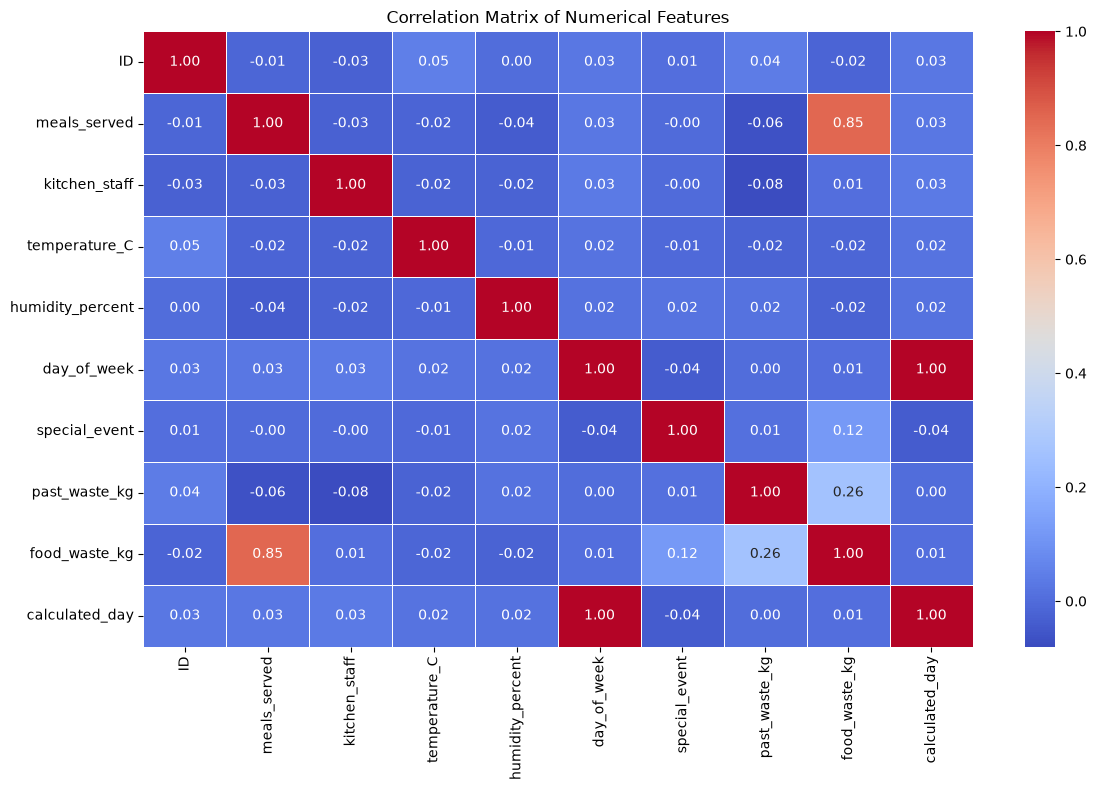

In [23]:
numerical_df = train_df.select_dtypes(include=["number"])

correlation_matrix = numerical_df.corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Matrix of Numerical Features")
plt.tight_layout()
plt.show()

In [24]:
target_correlation = (
    correlation_matrix["food_waste_kg"]
    .drop("food_waste_kg")
    .sort_values(ascending=False)
)

display(target_correlation)

meals_served        0.852128
past_waste_kg       0.260767
special_event       0.118757
day_of_week         0.008090
calculated_day      0.008090
kitchen_staff       0.007192
temperature_C      -0.015911
ID                 -0.020233
humidity_percent   -0.021793
Name: food_waste_kg, dtype: float64

Your correlation results give us a useful first understanding of the dataset. The strongest relationship is between meals_served and food_waste_kg.

Prepare the date and categorical columns

In [25]:
# Create a separate working copy
df = train_df.copy()

# Convert date to datetime format
df["date"] = pd.to_datetime(df["date"])

# Standardize categorical values
df["staff_experience"] = (
    df["staff_experience"]
    .str.strip()
    .str.lower()
)

df["waste_category"] = (
    df["waste_category"]
    .str.strip()
    .str.lower()
)

# Fill missing staff experience
df["staff_experience"] = (
    df["staff_experience"]
    .fillna("unknown")
)

# Extract calendar features
df["month"] = df["date"].dt.month
df["day_of_month"] = df["date"].dt.day

# Display the cleaned data
display(df.head())

print("Dataset shape:", df.shape)

print("\nMissing values:")
display(df.isnull().sum())

print("\nStaff experience categories:")
print(df["staff_experience"].value_counts())

print("\nWaste categories:")
print(df["waste_category"].value_counts())

,ID,date,meals_served,kitchen_staff,temperature_C,humidity_percent,day_of_week,special_event,past_waste_kg,staff_experience,waste_category,food_waste_kg,calculated_day,month,day_of_month
0,0,2022-12-19,196,13,27.887273,45.362854,0,0,7.740587,intermediate,dairy,28.946465,0,12,19
1,1,2023-11-21,244,15,10.317872,64.430475,1,0,42.311779,unknown,meat,51.549053,1,11,21
2,4,2022-02-01,148,16,27.714300,69.046113,1,0,41.184305,beginner,meat,53.008323,1,2,1
3,5,2023-03-19,157,19,19.173902,46.292823,6,0,41.543492,beginner,meat,48.621527,6,3,19
4,6,2022-07-18,297,10,26.375233,79.741064,0,0,26.525097,intermediate,meat,44.156984,0,7,18


Dataset shape: (911, 15)

Missing values:


ID                  0
date                0
meals_served        0
kitchen_staff       0
temperature_C       0
humidity_percent    0
day_of_week         0
special_event       0
past_waste_kg       0
staff_experience    0
waste_category      0
food_waste_kg       0
calculated_day      0
month               0
day_of_month        0
dtype: int64


Staff experience categories:
staff_experience
intermediate    370
beginner        191
expert          186
unknown         164
Name: count, dtype: int64

Waste categories:
waste_category
meat          379
dairy         180
vegetables    176
grains        176
Name: count, dtype: int64


Create a chronological training and testing split

In [26]:
# Sort unique dates chronologically
unique_dates = sorted(df["date"].unique())

# Calculate the 80% date cutoff
split_index = int(len(unique_dates) * 0.80)

# Identify the cutoff date
cutoff_date = unique_dates[split_index]

# Split records based on date
train_data = df[df["date"] < cutoff_date].copy()
test_data = df[df["date"] >= cutoff_date].copy()

# Display split information
print("Total records:", len(df))
print("Total unique dates:", len(unique_dates))

print("\nCutoff date:", cutoff_date)

print("\nTraining records:", len(train_data))
print("Testing records:", len(test_data))

print("\nTraining date range:")
print(train_data["date"].min(), "to", train_data["date"].max())

print("\nTesting date range:")
print(test_data["date"].min(), "to", test_data["date"].max())

# Verify that no date overlaps
overlap = set(train_data["date"]).intersection(set(test_data["date"]))

print("\nOverlapping dates:", len(overlap))

Total records: 911
Total unique dates: 867

Cutoff date: 2024-03-11 00:00:00

Training records: 737
Testing records: 174

Training date range:
2022-01-01 00:00:00 to 2024-03-10 00:00:00

Testing date range:
2024-03-11 00:00:00 to 2024-09-26 00:00:00

Overlapping dates: 0


Separate features and target

In [27]:
# Define columns that should not be used as input features
columns_to_drop = [
    "ID",
    "date",
    "calculated_day",
    "food_waste_kg"
]

# Separate features and target
X_train = train_data.drop(columns=columns_to_drop)
y_train = train_data["food_waste_kg"]

X_test = test_data.drop(columns=columns_to_drop)
y_test = test_data["food_waste_kg"]

# Verify the shapes
print("Training features:", X_train.shape)
print("Training target:", y_train.shape)

print("\nTesting features:", X_test.shape)
print("Testing target:", y_test.shape)

print("\nFeature columns:")
print(X_train.columns.tolist())

print("\nTarget variable:", y_train.name)

Training features: (737, 11)
Training target: (737,)

Testing features: (174, 11)
Testing target: (174,)

Feature columns:
['meals_served', 'kitchen_staff', 'temperature_C', 'humidity_percent', 'day_of_week', 'special_event', 'past_waste_kg', 'staff_experience', 'waste_category', 'month', 'day_of_month']

Target variable: food_waste_kg


In [28]:
# Save the processed training and testing datasets
train_data.to_csv("../data/train_processed.csv", index=False)
test_data.to_csv("../data/test_processed.csv", index=False)

print("Files saved successfully!")

print("\nTraining file:")
print("../data/train_processed.csv")

print("\nTesting file:")
print("../data/test_processed.csv")

Files saved successfully!

Training file:
../data/train_processed.csv

Testing file:
../data/test_processed.csv


In [29]:
import os

train_path = "../data/train_processed.csv"
test_path = "../data/test_processed.csv"

print("Training file exists:", os.path.exists(train_path))
print("Testing file exists:", os.path.exists(test_path))

# Load the saved files again
saved_train = pd.read_csv(train_path)
saved_test = pd.read_csv(test_path)

print("\nSaved training shape:", saved_train.shape)
print("Saved testing shape:", saved_test.shape)

Training file exists: True
Testing file exists: True

Saved training shape: (737, 15)
Saved testing shape: (174, 15)
